training samples: 2448
skipped samples: 2
validation samples: 524
test samples: 524
last batch shapes: torch.Size([12, 5, 56, 56]) torch.Size([12, 1, 56, 56])
last sample shapes: torch.Size([5, 56, 56]) torch.Size([1, 56, 56])


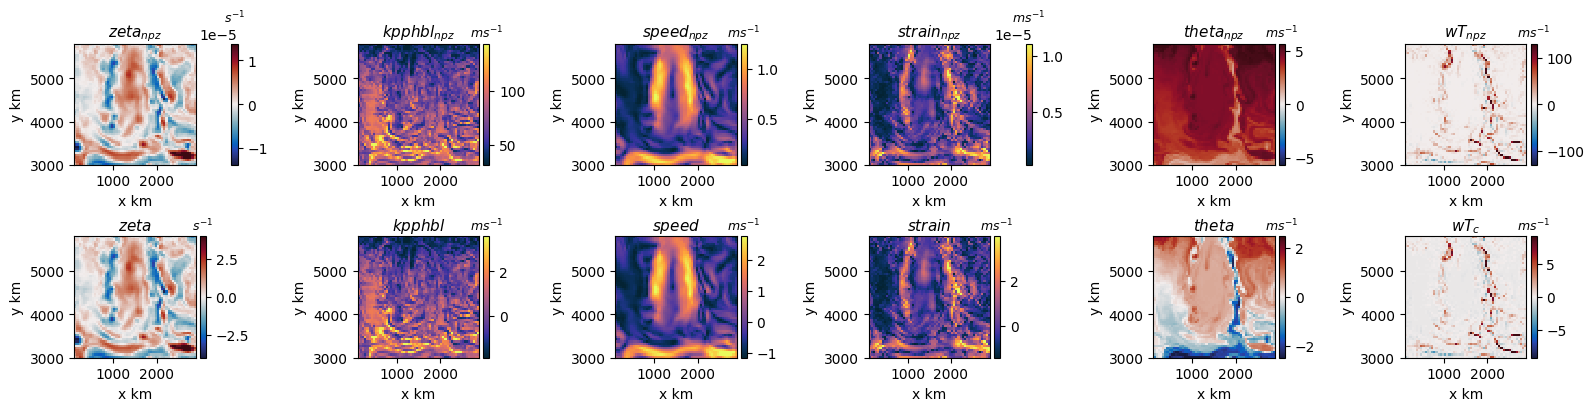

In [28]:
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from scr.utils import read_mitgcm
from scr.utils import build_coarse_grid
from scr.utils import data_loader

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]
features = np.load("/scratch/jczhang/submeso_data_driven/src/data/X.npy")
labels = np.load("/scratch/jczhang/submeso_data_driven/src/data/y.npy")
device = None
train_loader, val_loader, test_loader, norm = data_loader.prepare_data(
    features, labels, device, batch_size=32, num_workers=0, 
    frac_train=0.7, frac_skip=0, frac_val=0.15,  frac_test=0.15,
    shuffle= False, normalize_x=True, normalize_y=True)

# get last batch
for Xb, yb in test_loader:
    pass  # get the last batch 

# last sample in that last batch
x_last = Xb[-1]   # shape (C, H, W)
y_last = yb[-1]   # shape (1, H, W) 

print("last batch shapes:", Xb.shape, yb.shape)
print("last sample shapes:", x_last.shape, y_last.shape)
    
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# load the npz data
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/zeta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    zeta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/div.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    div_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/kpphbl.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    kpphbl_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/speed.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    speed_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/strain.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    strain_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/theta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    theta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/wT.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)        # (Nt,)
    wT_npz = npz["data"].astype(np.float32)       # (Nt, j, i)

# position
pos = -1
x1, x2 = 60,  116
y1, y2 = 2, 58
dx = 30
# plot 
fields = {
    r"$zeta_{npz}$":         {"Z": zeta_npz[pos,30:86, 1:57],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$kpphbl_{npz}$":         {"Z": kpphbl_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$speed_{npz}$":         {"Z": speed_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$strain_{npz}$":         {"Z": strain_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$theta_{npz}$":         {"Z": theta_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_{npz}$":         {"Z": wT_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    
    r"$zeta$":         {"Z": x_last[0,:,:],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$kpphbl$":         {"Z": x_last[3,:,:],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$speed$":         {"Z": x_last[4,:,:],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$strain$":         {"Z": x_last[1,:,:],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$theta$":         {"Z": x_last[2,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_c$":         {"Z": y_last[0,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(2,6, figsize=(16, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_last.png")
plt.show()